## 1. Scientific objective of the notebook

The thesis studies an age-structured model for mosquito eggs. The unknown is

$$
u(t,a),
$$

where $t$ is time, $a$ is the age of the eggs, and $u(t,a)$ is the egg density.

The deterministic model is

$$
\partial_t u(t,a)+v\partial_a u(t,a)=-\mu u(t,a),
$$

with the renewal boundary condition

$$
u(t,0)=\beta\int_0^A u(t,a)\,da.
$$

The parameters are:

- $v$: development velocity;
- $\mu$: mortality rate;
- $\beta$: fertility rate.

The numerical objective is to answer the following question:

> If we observe or simulate the egg density $u(t,a)$, can we reconstruct $v$, $\mu$, and $\beta$?

The notebook follows this logical order:

1. generate deterministic synthetic data using known parameters;
2. estimate $v$, $\mu$, and $\beta$ using the corrected formulas;
3. test the effect of observational noise;
4. simulate the stochastic model;
5. verify the finite-time mean-square stability numerically;
6. estimate parameters from stochastic data;
7. reconstruct the stochastic solution with estimated parameters;
8. compare the observed stochastic solution with the reconstructed stochastic solution.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Numerical setup

We choose numerical values for the simulation. These values are not intended to be a biological calibration. They are chosen to give a stable and clear numerical illustration.

The age interval is

$$
0\leq a\leq A.
$$

The time interval is

$$
0\leq t\leq T_{\max}.
$$

The discretization is

$$
t^n=n\Delta t,\qquad a_j=j\Delta a.
$$

We choose $\Delta t$ and $\Delta a$ so that the transport ratio

$$
r=\frac{v\Delta t}{\Delta a}
$$

is smaller than 1. This helps the explicit transport part of the semi-implicit scheme remain stable.

In [2]:
A_MAX = 15.0          
T_MAX = 20.0          
N_AGE = 100           
DT = 0.025            

DA = A_MAX / N_AGE
N_TIME = int(round(T_MAX / DT))

ages = np.linspace(0.0, A_MAX, N_AGE + 1)
times = np.linspace(0.0, N_TIME * DT, N_TIME + 1)

V_TRUE = 0.50
MU_TRUE = 0.08
BETA_TRUE = 0.015

r_true = V_TRUE * DT / DA

print(f"Transport ratio r    = {r_true:.5f}")

Transport ratio r    = 0.08333


## 3. Semi-implicit Euler scheme

We use a semi-implicit Euler scheme. The transport term is treated explicitly, while the mortality term is treated implicitly:

$$
\frac{u_j^{n+1}-u_j^n}{\Delta t}
+
\frac{v(u_j^n-u_{j-1}^n)}{\Delta a}
=
-\mu u_j^{n+1}.
$$

This gives

$$
u_j^{n+1}
=
\frac{
u_j^n-\frac{\Delta t}{\Delta a}v(u_j^n-u_{j-1}^n)}{1+\mu\Delta t}.
$$

The boundary condition is discretized by the trapezoidal rule:

$$
u_0^{n+1}
=
\beta\Delta a\sum_{j=0}^{N_a}\omega_j u_j^n.
$$

In [3]:
def trapezoidal_weights(n_age):
    omega = np.ones(n_age + 1)
    omega[0] = 0.5
    omega[-1] = 0.5
    return omega


def initial_condition(a):
    return 6.0 + 14.0 * np.exp(-((a - 3.0) ** 2) / 5.0)


def solve_deterministic_constant(v, mu, beta, ages, times, dt, da, clip_nonnegative=True):
    n_time = len(times) - 1
    n_age = len(ages) - 1
    omega = trapezoidal_weights(n_age)

    U = np.zeros((n_time + 1, n_age + 1))
    U[0, :] = initial_condition(ages)
    U[0, 0] = beta * da * np.sum(omega * U[0, :])

    r = v * dt / da
    if r > 1:
        print("Warning: v*dt/da is larger than 1. The explicit transport part may be unstable.")

    for n in range(n_time):
        U[n + 1, 0] = beta * da * np.sum(omega * U[n, :])
        U[n + 1, 1:] = (U[n, 1:] - r * (U[n, 1:] - U[n, :-1])) / (1.0 + mu * dt)
        if clip_nonnegative:
            U[n + 1, :] = np.maximum(U[n + 1, :], 0.0)

    return U

## 4. Corrected least squares estimators

We define

$$
u^n=\sum_{j=1}^{N_a}u_j^n,
\qquad
u_J^n=\sum_{j=1}^{N_a}u_{j-1}^n,
\qquad
D_n=u^n-u_J^n.
$$

The corrected estimator of $\mu$ is

$$
\widehat{\mu}
=
\frac{1}{\Delta t}
\left(
\frac{
\left(\sum_n u^nD_n\right)^2
-
\left(\sum_n (u^n)^2\right)
\left(\sum_n D_n^2\right)
}{
\left(\sum_n u^nD_n\right)
\left(\sum_n u^{n+1}D_n\right)
-
\left(\sum_n u^n u^{n+1}\right)
\left(\sum_n D_n^2\right)
}
-1
\right).
$$

Then

$$
\widehat{v}
=
\frac{
\Delta a(1+\widehat{\mu}\Delta t)
\sum_n D_n
\left(
\frac{u^n}{1+\widehat{\mu}\Delta t}
-
u^{n+1}
\right)
}{
\Delta t\sum_n D_n^2
}.
$$

For the fertility parameter,

$$
\widehat{\beta}_n
=
\frac{u_0^{n+1}}
{\Delta a\sum_{j=0}^{N_a}\omega_j u_j^n}.
$$

This gives one value $\widehat\beta_n$ at each time step. In summary tables, we report the mean of these pointwise estimates.

In [4]:
def compute_aggregated_quantities(U):
    u_n = U[:-1, 1:].sum(axis=1)
    u_J_n = U[:-1, :-1].sum(axis=1)
    u_np1 = U[1:, 1:].sum(axis=1)
    return u_n, u_J_n, u_np1


def estimate_mu_corrected_formula(U, dt):
    u_n, u_J_n, u_np1 = compute_aggregated_quantities(U)
    D = u_n - u_J_n

    SUD = np.sum(u_n * D)
    SUU = np.sum(u_n ** 2)
    SDD = np.sum(D ** 2)
    SYD = np.sum(u_np1 * D)
    SUY = np.sum(u_n * u_np1)

    numerator = (SUD ** 2) - (SUU * SDD)
    denominator = (SUD * SYD) - (SUY * SDD)

    if abs(denominator) < 1e-14:
        raise ValueError("The denominator in the mu estimator is too close to zero.")

    return (1.0 / dt) * (numerator / denominator - 1.0)


def estimate_v_corrected_formula(U, dt, da, mu_hat):
    u_n, u_J_n, u_np1 = compute_aggregated_quantities(U)
    D = u_n - u_J_n

    denominator = dt * np.sum(D ** 2)
    if abs(denominator) < 1e-14:
        raise ValueError("The denominator in the v estimator is too close to zero.")

    numerator = da * (1.0 + mu_hat * dt) * np.sum(
        D * ((u_n / (1.0 + mu_hat * dt)) - u_np1)
    )
    return numerator / denominator


def estimate_beta_pointwise_formula(U, da, omega=None):
    n_age = U.shape[1] - 1
    if omega is None:
        omega = trapezoidal_weights(n_age)

    beta_values = []
    for n in range(U.shape[0] - 1):
        numerator = U[n + 1, 0]
        denominator = da * np.sum(omega * U[n, :])
        beta_values.append(np.nan if abs(denominator) < 1e-14 else numerator / denominator)
    return np.array(beta_values)


def estimate_parameters_corrected(U, dt, da, omega=None):
    mu_hat = estimate_mu_corrected_formula(U, dt)
    v_hat = estimate_v_corrected_formula(U, dt, da, mu_hat)
    beta_hat_all = estimate_beta_pointwise_formula(U, da, omega=omega)
    return {
        "v_hat": v_hat,
        "mu_hat": mu_hat,
        "beta_hat_all": beta_hat_all,
        "beta_hat_mean": np.nanmean(beta_hat_all)
    }


def relative_error(estimated, true_value):
    return abs(estimated - true_value) / abs(true_value)


def parameter_summary(estimates, true_params):
    rows = []
    rows.append({"Parameter": "v", "True value": true_params["v"], "Estimated value": estimates["v_hat"],
                 "Absolute error": abs(estimates["v_hat"] - true_params["v"]),
                 "Relative error": relative_error(estimates["v_hat"], true_params["v"])})
    rows.append({"Parameter": "mu", "True value": true_params["mu"], "Estimated value": estimates["mu_hat"],
                 "Absolute error": abs(estimates["mu_hat"] - true_params["mu"]),
                 "Relative error": relative_error(estimates["mu_hat"], true_params["mu"])})
    rows.append({"Parameter": "beta_mean", "True value": true_params["beta"], "Estimated value": estimates["beta_hat_mean"],
                 "Absolute error": abs(estimates["beta_hat_mean"] - true_params["beta"]),
                 "Relative error": relative_error(estimates["beta_hat_mean"], true_params["beta"])})
    return pd.DataFrame(rows)

true_params = {"v": V_TRUE, "mu": MU_TRUE, "beta": BETA_TRUE}

## 5. Deterministic reconstruction with constant parameters

We first generate synthetic data with the true parameters. This is the simplest validation test.

If the formulas are correct and the data are generated by the same numerical model, the estimated parameters should be very close to the true parameters.

In [5]:
U_det = solve_deterministic_constant(
    v=V_TRUE,
    mu=MU_TRUE,
    beta=BETA_TRUE,
    ages=ages,
    times=times,
    dt=DT,
    da=DA
)

print("Deterministic simulation completed.")
print("Shape of U_det:", U_det.shape)
print("Minimum value:", U_det.min())
print("Maximum value:", U_det.max())

Deterministic simulation completed.
Shape of U_det: (801, 101)
Minimum value: 0.2835912318579891
Maximum value: 20.0


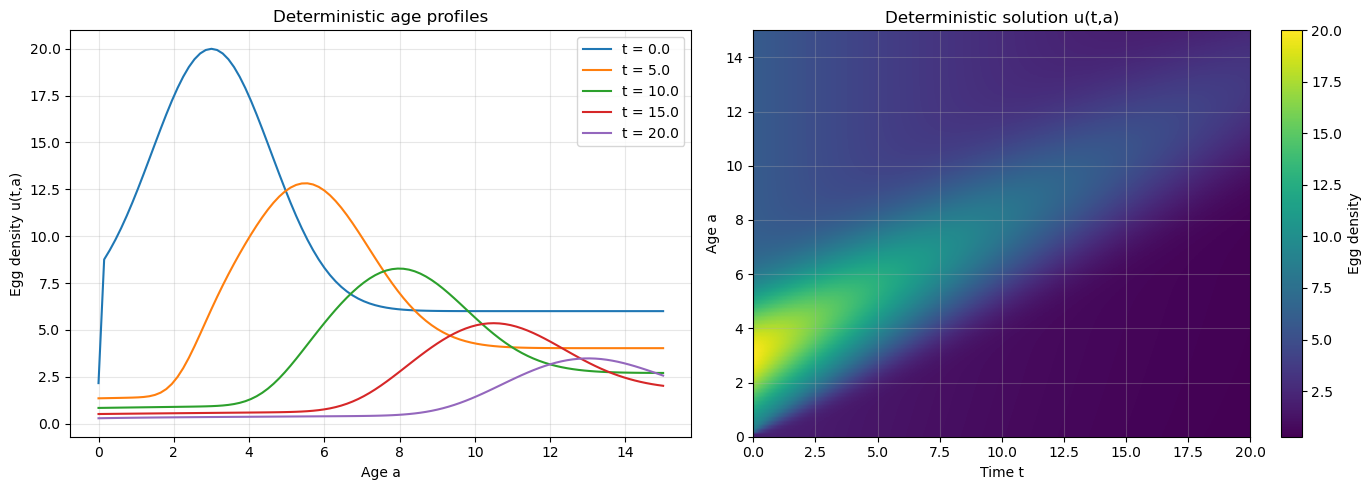

In [6]:
selected_indices = [0, int(0.25 * N_TIME), int(0.50 * N_TIME), int(0.75 * N_TIME), N_TIME]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Figure 1 : profils en âge
for idx in selected_indices:
    axes[0].plot(ages, U_det[idx, :], label=f"t = {times[idx]:.1f}")

axes[0].set_xlabel("Age a")
axes[0].set_ylabel("Egg density u(t,a)")
axes[0].set_title("Deterministic age profiles")
axes[0].legend()

# Figure 2 : solution déterministe sous forme d'image
im = axes[1].imshow(
    U_det.T,
    aspect="auto",
    origin="lower",
    extent=[times[0], times[-1], ages[0], ages[-1]]
)

axes[1].set_xlabel("Time t")
axes[1].set_ylabel("Age a")
axes[1].set_title("Deterministic solution u(t,a)")

# Barre de couleur
fig.colorbar(im, ax=axes[1], label="Egg density")

plt.tight_layout()

plt.savefig("Deterministic solution u(t,a).pdf",bbox_inches="tight")
plt.show()

In [7]:
est_det = estimate_parameters_corrected(U_det, dt=DT, da=DA)
summary_det = parameter_summary(est_det, true_params)
display(summary_det)

print("First five beta estimates:")
print(est_det["beta_hat_all"][:5])

,Parameter,True value,Estimated value,Absolute error,Relative error
0,v,0.500,0.500,3.232137e-12,6.464274e-12
1,mu,0.080,0.080,1.066508e-13,1.333135e-12
2,beta_mean,0.015,0.015,0.000000e+00,0.000000e+00


First five beta estimates:
[0.015 0.015 0.015 0.015 0.015]


### Interpretation

In the deterministic case, the errors should be very small. This validates the corrected algebraic formulas and the numerical implementation.

This result does not prove that the method will be perfect on real data. It only shows that the estimator is coherent with the simulated model.

## 6. Robustness under observational noise

Real data are rarely exact. Measurements may contain errors. We model this by adding observational noise:

$$
Y_j^n=u_j^n+\eta_j^n.
$$

This noise is not part of the biological dynamics. It represents errors in observation or measurement.

We test several noise levels. For each noise level, we repeat the random experiment many times. This repeated random experiment is called a **Monte Carlo method**.

### What is the Monte Carlo method?

The Monte Carlo method means that we repeat a random experiment many times and average the results. For example, if we want to know the typical error of $\widehat v$, we generate many noisy datasets, estimate $v$ for each dataset, and compute the average error.

The larger the number of repetitions, the more reliable the Monte Carlo average becomes.

In [8]:
def add_observational_noise(U, sigma, seed=0, relative_scale=True):
    rng = np.random.default_rng(seed)
    scale = max(np.mean(U), 1e-12) if relative_scale else 1.0
    Y = U + sigma * scale * rng.normal(size=U.shape)
    return np.maximum(Y, 0.0)


def monte_carlo_observational_noise(U_reference, noise_levels, n_mc, dt, da, seed=2026):
    base_rng = np.random.default_rng(seed)
    rows = []

    for sigma in noise_levels:
        estimates = {"v": [], "mu": [], "beta_mean": []}

        for _ in range(n_mc):
            local_seed = int(base_rng.integers(0, 1_000_000_000))
            Y = add_observational_noise(U_reference, sigma=sigma, seed=local_seed)
            try:
                est = estimate_parameters_corrected(Y, dt=dt, da=da)
                estimates["v"].append(est["v_hat"])
                estimates["mu"].append(est["mu_hat"])
                estimates["beta_mean"].append(est["beta_hat_mean"])
            except Exception:
                estimates["v"].append(np.nan)
                estimates["mu"].append(np.nan)
                estimates["beta_mean"].append(np.nan)

        for name, true_value in [("v", V_TRUE), ("mu", MU_TRUE), ("beta_mean", BETA_TRUE)]:
            values = np.array(estimates[name], dtype=float)
            values = values[np.isfinite(values)]
            mean_est = np.mean(values)
            bias = mean_est - true_value
            variance = np.var(values, ddof=1) if len(values) > 1 else 0.0
            mse = np.mean((values - true_value) ** 2)
            rows.append({"Noise level": sigma, "Parameter": name, "True value": true_value,
                         "Mean estimate": mean_est, "Bias": bias, "Variance": variance,
                         "MSE": mse, "Relative bias": bias / true_value})

    return pd.DataFrame(rows)

noise_levels = [0.005, 0.01, 0.03, 0.05, 0.1]
N_MC_OBS = 40

obs_noise_results = monte_carlo_observational_noise(U_det, noise_levels, N_MC_OBS, DT, DA)
display(obs_noise_results)

,Noise level,Parameter,True value,Mean estimate,Bias,Variance,MSE,Relative bias
0,0.005,v,0.500,0.502387,0.002387,8.685959e-05,9.038664e-05,0.004774
1,0.005,mu,0.080,0.079915,-0.000085,8.601545e-08,9.113741e-08,-0.001066
2,0.005,beta_mean,0.015,0.014999,-0.000001,2.214253e-10,2.174611e-10,-0.000084
3,0.010,v,0.500,0.505968,0.005968,7.829591e-04,7.990017e-04,0.011936
4,0.010,mu,0.080,0.079859,-0.000141,7.265889e-07,7.283714e-07,-0.001765
5,0.010,beta_mean,0.015,0.014993,-0.000007,9.831900e-10,1.014814e-09,-0.000500
6,0.030,v,0.500,0.594062,0.094062,5.171738e-02,5.927207e-02,0.188124
7,0.030,mu,0.080,0.077419,-0.002581,4.898279e-05,5.441924e-05,-0.032261
8,0.030,beta_mean,0.015,0.014997,-0.000003,1.728154e-08,1.685817e-08,-0.000196
9,0.050,v,0.500,0.739747,0.239747,1.687381e-01,2.219980e-01,0.479493


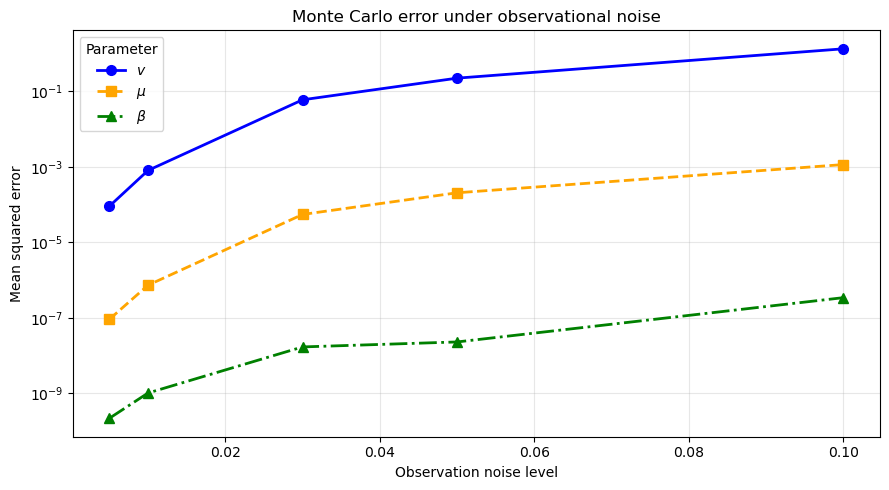

In [9]:
plt.figure(figsize=(9, 5))

plot_styles = {
    "v": {
        "color": "blue",
        "marker": "o",
        "linestyle": "-",
        "label": r"$v$"
    },
    "mu": {
        "color": "orange",
        "marker": "s",
        "linestyle": "--",
        "label": r"$\mu$"
    },
    "beta_mean": {
        "color": "green",
        "marker": "^",
        "linestyle": "-.",
        "label": r"$\beta$"
    }
}

for name, style in plot_styles.items():
    sub = obs_noise_results[obs_noise_results["Parameter"] == name]
    
    plt.plot(
        sub["Noise level"],
        sub["MSE"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=2,
        markersize=7,
        label=style["label"]
    )

plt.yscale("log")

plt.xlabel("Observation noise level")
plt.ylabel("Mean squared error")
plt.title("Monte Carlo error under observational noise")

plt.grid(True, alpha=0.3, which="both")
plt.legend(title="Parameter")
plt.tight_layout()

plt.savefig("Monte Carlo error under observational noise(1).pdf",bbox_inches="tight")
plt.show()

### Interpretation

The figure shows the Monte Carlo mean squared error of the estimated parameters under observational noise. As expected, the estimation error increases when the noise level increases. This confirms that observational noise affects the accuracy of the parameter reconstruction. However, the increase remains progressive, which suggests that the estimation method is reasonably robust for small and moderate noise levels.

The errors associated with $v$ and $\mu$ are very close, which explains why their curves may overlap in the standard plot. This indicates that the estimators of $v$ and $\mu$ have similar sensitivity with respect to observational noise. The logarithmic scale gives a clearer visualization of the small differences between these two parameters. If the curve associated with $\beta$ is higher, then $\beta$ is more sensitive to observational noise than $v$ and $\mu$. Conversely, if $\beta$ remains close to the others, this suggests that all three estimators have comparable robustness.

## 7. Stochastic model and finite-dimensional noise

The stochastic model is

$$
du^\varepsilon(t)=[-v\partial_a u^\varepsilon(t)-\mu u^\varepsilon(t)]dt+\varepsilon GdW(t).
$$

A computer cannot simulate an infinite-dimensional Wiener process exactly. Therefore, we use a finite-dimensional smooth approximation of the noise. We build sine modes and generate random coefficients.

The noise is added to the interior grid points only. The boundary value is recomputed from the renewal condition.

In [10]:
def build_noise_modes(ages, n_modes=8):
    A = ages[-1]
    modes = []
    eigenvalues = []
    for k in range(1, n_modes + 1):
        phi_k = np.sqrt(2.0 / A) * np.sin(k * np.pi * ages / A)
        lambda_k = 1.0 / (k ** 2)
        modes.append(phi_k)
        eigenvalues.append(lambda_k)
    return np.array(modes), np.array(eigenvalues)


def generate_noise_path(ages, n_time, seed=0, n_modes=8):
    rng = np.random.default_rng(seed)
    modes, eigenvalues = build_noise_modes(ages, n_modes=n_modes)
    noise_path = np.zeros((n_time, len(ages)))
    for n in range(n_time):
        coefficients = rng.normal(size=n_modes) * np.sqrt(eigenvalues)
        noise_path[n, :] = coefficients @ modes
    noise_path[:, 0] = 0.0
    return noise_path


def solve_stochastic_with_given_noise(v, mu, beta, epsilon, noise_path, ages, times, dt, da, clip_nonnegative=True):
    n_time = len(times) - 1
    n_age = len(ages) - 1
    omega = trapezoidal_weights(n_age)

    U = np.zeros((n_time + 1, n_age + 1))
    U[0, :] = initial_condition(ages)
    U[0, 0] = beta * da * np.sum(omega * U[0, :])
    r = v * dt / da

    for n in range(n_time):
        U[n + 1, 0] = beta * da * np.sum(omega * U[n, :])
        U[n + 1, 1:] = (U[n, 1:] - r * (U[n, 1:] - U[n, :-1])) / (1.0 + mu * dt)
        if epsilon > 0:
            U[n + 1, 1:] += epsilon * np.sqrt(dt) * noise_path[n, 1:]
        if clip_nonnegative:
            U[n + 1, :] = np.maximum(U[n + 1, :], 0.0)
        U[n + 1, 0] = beta * da * np.sum(omega * U[n + 1, :])
    return U


def l2_squared_error(U1, U2, da):
    return da * np.sum((U1 - U2) ** 2, axis=1)

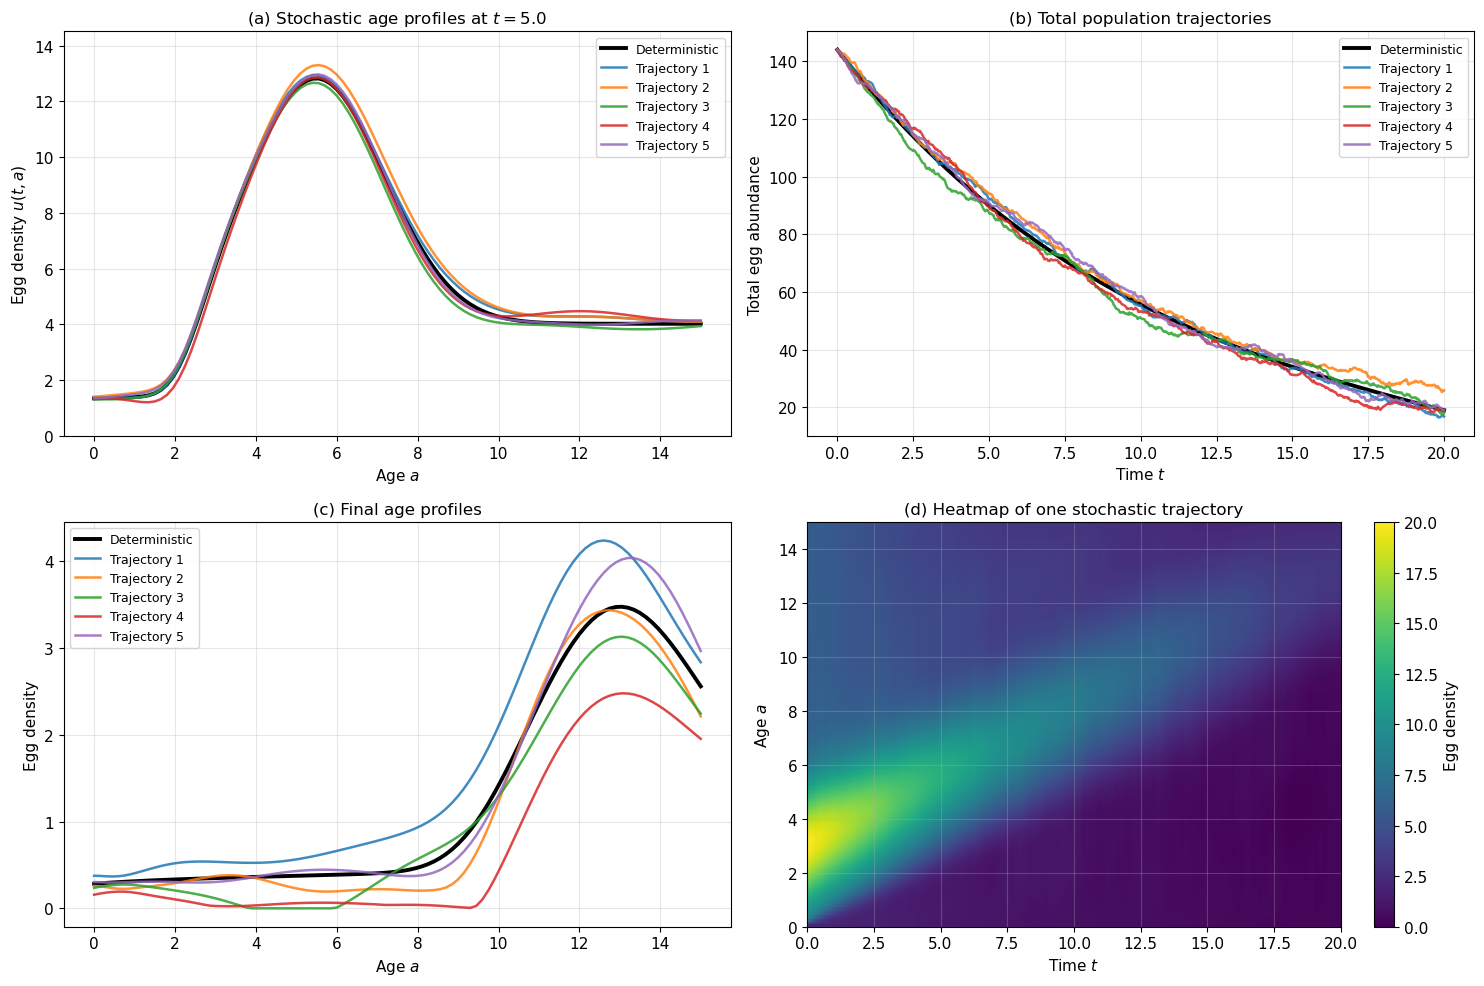

In [11]:
# Parameters

EPSILON_TRAJ = 0.5
N_TRAJ = 5
N_MODES_TRAJ = 8
t_fixed = 5.0

# Time index corresponding to t = 5.0

idx_t = np.argmin(np.abs(times - t_fixed))
t_selected = times[idx_t]


# Global style

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9
})

fig, axes = plt.subplots(2, 2, figsize=(15, 10))


# Figure 1: Age profiles at t = 5.0

ax = axes[0, 0]

all_profiles_t5 = []

det_profile_t5 = U_det[idx_t, :]
all_profiles_t5.append(det_profile_t5)

ax.plot(
    ages,
    det_profile_t5,
    color="black",
    linewidth=2.8,
    label="Deterministic"
)

for k in range(N_TRAJ):
    noise_path = generate_noise_path(
        ages=ages,
        n_time=N_TIME,
        seed=1000 + k,
        n_modes=N_MODES_TRAJ
    )

    U_stoch_k = solve_stochastic_with_given_noise(
        v=V_TRUE,
        mu=MU_TRUE,
        beta=BETA_TRUE,
        epsilon=EPSILON_TRAJ,
        noise_path=noise_path,
        ages=ages,
        times=times,
        dt=DT,
        da=DA,
        clip_nonnegative=True
    )

    profile_t5 = U_stoch_k[idx_t, :]
    all_profiles_t5.append(profile_t5)

    ax.plot(
        ages,
        profile_t5,
        linewidth=1.8,
        alpha=0.85,
        label=f"Trajectory {k+1}"
    )

# Adjust y-axis for better visibility
all_profiles_t5 = np.array(all_profiles_t5)
y_min = np.min(all_profiles_t5)
y_max = np.max(all_profiles_t5)
margin = 0.10 * (y_max - y_min) if y_max > y_min else 0.1
ax.set_ylim(y_min - margin, y_max + margin)

ax.set_xlabel("Age $a$")
ax.set_ylabel(r"Egg density $u(t,a)$")
ax.set_title(r"(a) Stochastic age profiles at $t=5.0$")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", frameon=True)


# Figure 2: Total population trajectories

ax = axes[0, 1]

total_det = DA * U_det.sum(axis=1)

ax.plot(
    times,
    total_det,
    color="black",
    linewidth=2.8,
    label="Deterministic"
)

for k in range(N_TRAJ):
    noise_path = generate_noise_path(
        ages=ages,
        n_time=N_TIME,
        seed=1000 + k,
        n_modes=N_MODES_TRAJ
    )

    U_stoch_k = solve_stochastic_with_given_noise(
        v=V_TRUE,
        mu=MU_TRUE,
        beta=BETA_TRUE,
        epsilon=EPSILON_TRAJ,
        noise_path=noise_path,
        ages=ages,
        times=times,
        dt=DT,
        da=DA,
        clip_nonnegative=True
    )

    total_stoch_k = DA * U_stoch_k.sum(axis=1)

    ax.plot(
        times,
        total_stoch_k,
        linewidth=1.8,
        alpha=0.85,
        label=f"Trajectory {k+1}"
    )

ax.set_xlabel("Time $t$")
ax.set_ylabel("Total egg abundance")
ax.set_title("(b) Total population trajectories")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", frameon=True)


# Figure 3: Final age profiles

ax = axes[1, 0]

ax.plot(
    ages,
    U_det[-1, :],
    color="black",
    linewidth=2.8,
    label="Deterministic"
)

for k in range(N_TRAJ):
    noise_path = generate_noise_path(
        ages=ages,
        n_time=N_TIME,
        seed=2000 + k,
        n_modes=N_MODES_TRAJ
    )

    U_stoch_k = solve_stochastic_with_given_noise(
        v=V_TRUE,
        mu=MU_TRUE,
        beta=BETA_TRUE,
        epsilon=EPSILON_TRAJ,
        noise_path=noise_path,
        ages=ages,
        times=times,
        dt=DT,
        da=DA,
        clip_nonnegative=True
    )

    ax.plot(
        ages,
        U_stoch_k[-1, :],
        linewidth=1.8,
        alpha=0.85,
        label=f"Trajectory {k+1}"
    )

ax.set_xlabel("Age $a$")
ax.set_ylabel("Egg density")
ax.set_title("(c) Final age profiles")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", frameon=True)


# Figure 4: Heatmap of one stochastic trajectory

ax = axes[1, 1]

noise_path = generate_noise_path(
    ages=ages,
    n_time=N_TIME,
    seed=3000,
    n_modes=N_MODES_TRAJ
)

U_stoch_one = solve_stochastic_with_given_noise(
    v=V_TRUE,
    mu=MU_TRUE,
    beta=BETA_TRUE,
    epsilon=EPSILON_TRAJ,
    noise_path=noise_path,
    ages=ages,
    times=times,
    dt=DT,
    da=DA,
    clip_nonnegative=True
)

im = ax.imshow(
    U_stoch_one.T,
    aspect="auto",
    origin="lower",
    extent=[times[0], times[-1], ages[0], ages[-1]]
)

ax.set_xlabel("Time $t$")
ax.set_ylabel("Age $a$")
ax.set_title(r"(d) Heatmap of one stochastic trajectory")
fig.colorbar(im, ax=ax, label="Egg density")


# Final layout

plt.tight_layout()

plt.savefig("stochastic trajectories.pdf",bbox_inches="tight")
plt.show()

## 8. Numerical illustration of stochastic stability

The theoretical result says that, for small $\varepsilon$,

$$
\mathbb{E}\|u^\varepsilon(t)-u(t)\|^2\leq C_T\varepsilon^2.
$$

We estimate the expectation using Monte Carlo simulations. For each value of $\varepsilon$, we generate many stochastic trajectories and compute the average squared distance from the deterministic solution.

In [12]:
def monte_carlo_stability(U_reference, epsilons, n_mc, seed=123):
    base_rng = np.random.default_rng(seed)
    rows = []
    curves = {}
    for eps in epsilons:
        all_errors = []
        for _ in range(n_mc):
            local_seed = int(base_rng.integers(0, 1_000_000_000))
            noise_path = generate_noise_path(ages, N_TIME, seed=local_seed, n_modes=8)
            U_eps = solve_stochastic_with_given_noise(V_TRUE, MU_TRUE, BETA_TRUE, eps, noise_path, ages, times, DT, DA)
            all_errors.append(l2_squared_error(U_eps, U_reference, DA))
        all_errors = np.array(all_errors)
        mean_error = all_errors.mean(axis=0)
        curves[eps] = mean_error
        rows.append({"epsilon": eps, "epsilon^2": eps**2,
                     "final mean L2 squared error": mean_error[-1],
                     "max mean L2 squared error": mean_error.max(),
                     "final error / epsilon^2": mean_error[-1] / (eps**2)})
    return pd.DataFrame(rows), curves

EPSILONS = [0.01, 0.03, 0.05, 0.10]
N_MC_STAB = 40

stability_table, stability_curves = monte_carlo_stability(U_det, EPSILONS, N_MC_STAB)
display(stability_table)

,epsilon,epsilon^2,final mean L2 squared error,max mean L2 squared error,final error / epsilon^2
0,0.01,0.0001,0.000952,0.000967,9.521735
1,0.03,0.0009,0.005414,0.008007,6.015648
2,0.05,0.0025,0.027072,0.027315,10.828929
3,0.10,0.0100,0.068909,0.072123,6.890908


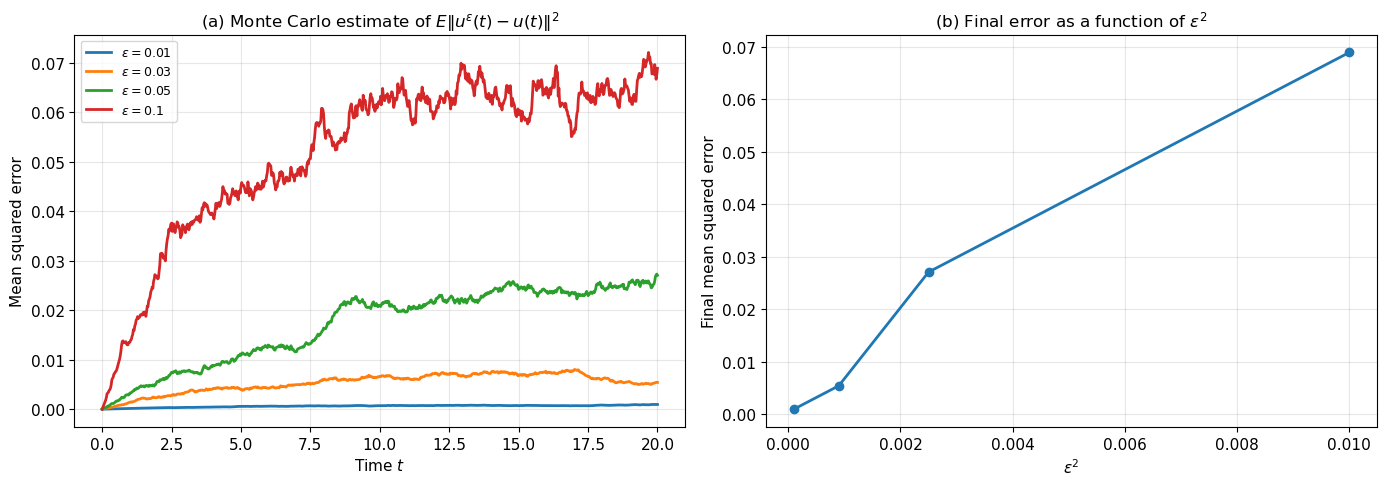

In [13]:
# Combined figure: numerical illustration of stochastic stability


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Figure 1: Monte Carlo estimate of the stability error

ax = axes[0]

for eps, curve in stability_curves.items():
    ax.plot(
        times,
        curve,
        linewidth=2,
        label=rf"$\epsilon = {eps}$"
    )

ax.set_xlabel("Time $t$")
ax.set_ylabel("Mean squared error")
ax.set_title(r"(a) Monte Carlo estimate of $E\|u^\epsilon(t)-u(t)\|^2$")
ax.legend()
ax.grid(True, alpha=0.3)


# Figure 2: Final error as a function of epsilon squared

ax = axes[1]

ax.plot(
    stability_table["epsilon^2"],
    stability_table["final mean L2 squared error"],
    marker="o",
    linewidth=2
)

ax.set_xlabel(r"$\epsilon^2$")
ax.set_ylabel("Final mean squared error")
ax.set_title(r"(b) Final error as a function of $\epsilon^2$")
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("stochastic Stability.pdf",bbox_inches="tight")
plt.show()

## 9. Parameter reconstruction from stochastic data

We now estimate $v$, $\mu$, and $\beta$ from stochastic data.

This answers the practical question: can the corrected estimators still recover the parameters when the data are affected by stochastic perturbations?

In [14]:
def monte_carlo_stochastic_reconstruction(epsilons, n_mc, seed=777):
    base_rng = np.random.default_rng(seed)
    rows = []
    for eps in epsilons:
        estimates = {"v": [], "mu": [], "beta_mean": []}
        for _ in range(n_mc):
            local_seed = int(base_rng.integers(0, 1_000_000_000))
            noise_path = generate_noise_path(ages, N_TIME, seed=local_seed, n_modes=8)
            U_eps = solve_stochastic_with_given_noise(V_TRUE, MU_TRUE, BETA_TRUE, eps, noise_path, ages, times, DT, DA)
            try:
                est = estimate_parameters_corrected(U_eps, DT, DA)
                estimates["v"].append(est["v_hat"])
                estimates["mu"].append(est["mu_hat"])
                estimates["beta_mean"].append(est["beta_hat_mean"])
            except Exception:
                estimates["v"].append(np.nan)
                estimates["mu"].append(np.nan)
                estimates["beta_mean"].append(np.nan)
        for name, true_value in [("v", V_TRUE), ("mu", MU_TRUE), ("beta_mean", BETA_TRUE)]:
            values = np.array(estimates[name], dtype=float)
            values = values[np.isfinite(values)]
            mean_est = np.mean(values)
            bias = mean_est - true_value
            variance = np.var(values, ddof=1) if len(values) > 1 else 0.0
            mse = np.mean((values - true_value) ** 2)
            rows.append({"epsilon": eps, "Parameter": name, "True value": true_value,
                         "Mean estimate": mean_est, "Bias": bias, "Variance": variance,
                         "MSE": mse, "Relative bias": bias / true_value})
    return pd.DataFrame(rows)

N_MC_RECON = 20
stoch_recon_results = monte_carlo_stochastic_reconstruction(EPSILONS, N_MC_RECON)
display(stoch_recon_results)

,epsilon,Parameter,True value,Mean estimate,Bias,Variance,MSE,Relative bias
0,0.01,v,0.500,0.497886,-0.002114,2.009098e-04,1.953332e-04,-0.004228
1,0.01,mu,0.080,0.080046,0.000046,2.380436e-07,2.282426e-07,0.000573
2,0.01,beta_mean,0.015,0.014962,-0.000038,5.366080e-15,1.440964e-09,-0.002531
3,0.03,v,0.500,0.494282,-0.005718,1.767168e-03,1.711508e-03,-0.011436
4,0.03,mu,0.080,0.080278,0.000278,1.969170e-06,1.947909e-06,0.003473
5,0.03,beta_mean,0.015,0.014962,-0.000038,5.144684e-14,1.443998e-09,-0.002533
6,0.05,v,0.500,0.491743,-0.008257,4.264948e-03,4.119883e-03,-0.016515
7,0.05,mu,0.080,0.080387,0.000387,3.733547e-06,3.696500e-06,0.004835
8,0.05,beta_mean,0.015,0.014962,-0.000038,2.323029e-13,1.447642e-09,-0.002536
9,0.10,v,0.500,0.476071,-0.023929,1.955360e-02,1.914851e-02,-0.047858


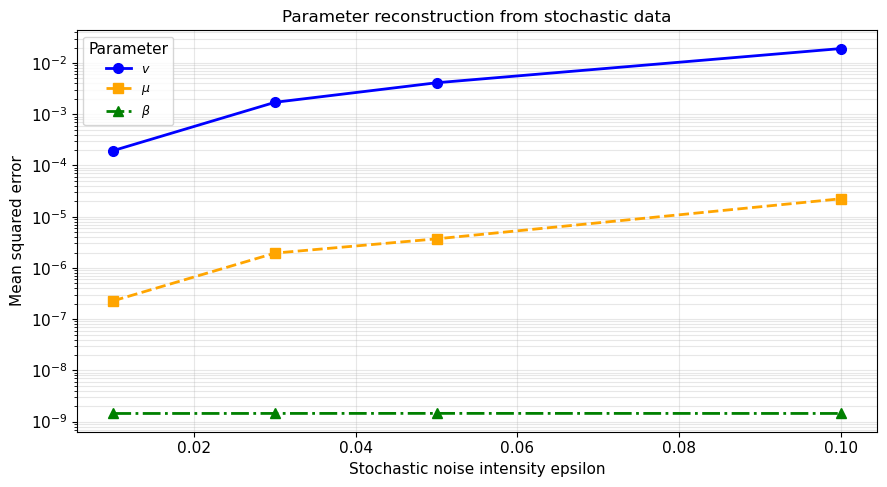

In [15]:
plt.figure(figsize=(9, 5))

plot_styles = {
    "v": {
        "color": "blue",
        "marker": "o",
        "linestyle": "-",
        "label": r"$v$"
    },
    "mu": {
        "color": "orange",
        "marker": "s",
        "linestyle": "--",
        "label": r"$\mu$"
    },
    "beta_mean": {
        "color": "green",
        "marker": "^",
        "linestyle": "-.",
        "label": r"$\beta$"
    }
}

for name, style in plot_styles.items():
    sub = stoch_recon_results[stoch_recon_results["Parameter"] == name]

   # plt.plot(sub["epsilon"], sub["MSE"], marker="o", label=name)
    
    plt.plot(
        sub["epsilon"],
        sub["MSE"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        linewidth=2,
        markersize=7,
        label=style["label"]
    )

plt.yscale("log")

plt.xlabel("Stochastic noise intensity epsilon")
plt.ylabel("Mean squared error")
plt.title("Parameter reconstruction from stochastic data")
plt.grid(True, alpha=0.3, which="both")
plt.legend(title="Parameter")
plt.tight_layout()

plt.savefig("Parameter reconstruction from stochastic data.pdf",bbox_inches="tight")
plt.show()


## 10. Reconstruction of the stochastic solution with estimated parameters

We now perform a pathwise reconstruction experiment.

1. Generate one stochastic solution with the true parameters. This is treated as the observed stochastic solution.
2. Estimate $v$, $\mu$, and $\beta$ from this stochastic solution.
3. Simulate a new stochastic solution using the estimated parameters.
4. Use the same noise path in both simulations.

Using the same noise path is important. If we used different noise paths, the difference between the two solutions would come from both parameter error and noise randomness. With the same noise path, the comparison mainly measures the effect of parameter reconstruction.

In [16]:
EPSILON_RECON = 0.1
RECON_SEED = 20260507

noise_path_recon = generate_noise_path(ages, N_TIME, seed=RECON_SEED, n_modes=8)

U_stoch_observed = solve_stochastic_with_given_noise(
    V_TRUE, MU_TRUE, BETA_TRUE, EPSILON_RECON,
    noise_path_recon, ages, times, DT, DA
)

est_from_stoch = estimate_parameters_corrected(U_stoch_observed, DT, DA)
display(parameter_summary(est_from_stoch, true_params))

v_est = est_from_stoch["v_hat"]
mu_est = est_from_stoch["mu_hat"]
beta_est = est_from_stoch["beta_hat_mean"]

print("Estimated parameters used for stochastic reconstruction:")
print(f"v_hat    = {v_est}")
print(f"mu_hat   = {mu_est}")
print(f"beta_hat = {beta_est}")

,Parameter,True value,Estimated value,Absolute error,Relative error
0,v,0.500,0.511436,0.011436,0.022872
1,mu,0.080,0.079627,0.000373,0.004657
2,beta_mean,0.015,0.014962,0.000038,0.002526


Estimated parameters used for stochastic reconstruction:
v_hat    = 0.5114362448909855
mu_hat   = 0.0796274527432228
beta_hat = 0.014962117026824474


In [17]:
U_stoch_reconstructed = solve_stochastic_with_given_noise(
    v_est, mu_est, beta_est, EPSILON_RECON,
    noise_path_recon, ages, times, DT, DA
)

reconstruction_error = l2_squared_error(U_stoch_reconstructed, U_stoch_observed, DA)

print("Stochastic reconstruction completed.")
print("Final L2 squared reconstruction error:", reconstruction_error[-1])
print("Maximum L2 squared reconstruction error:", reconstruction_error.max())

Stochastic reconstruction completed.
Final L2 squared reconstruction error: 0.13284249043709664
Maximum L2 squared reconstruction error: 0.29528207759800484


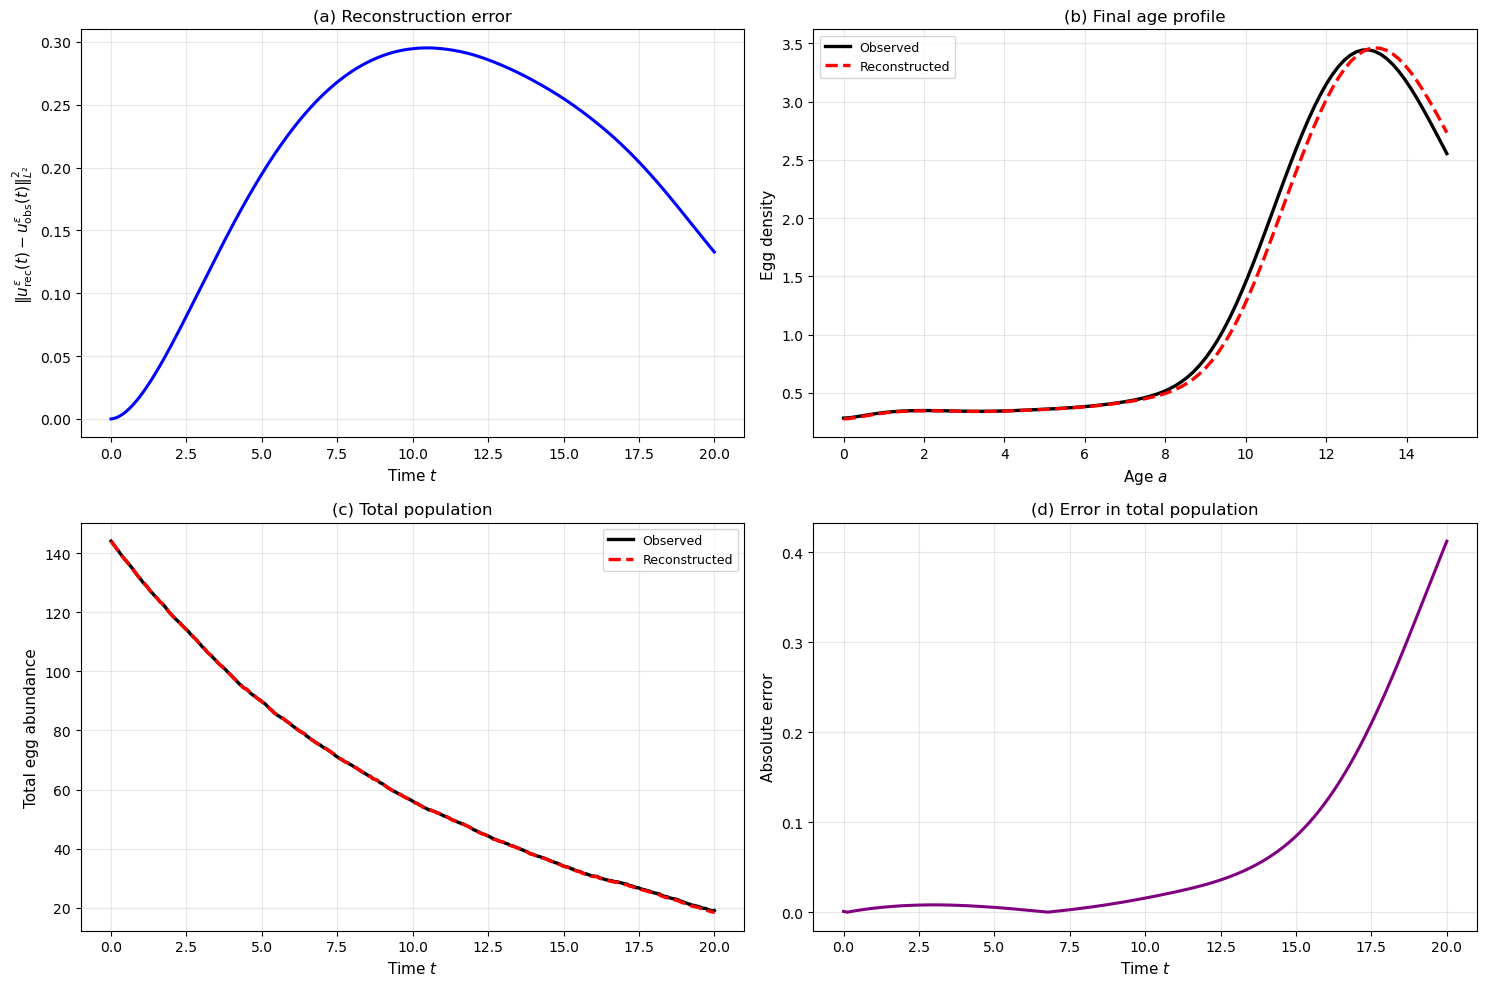

In [18]:
# ------------------------------------------------------------
# Global style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

# ------------------------------------------------------------
# Total populations
# ------------------------------------------------------------
total_observed = DA * U_stoch_observed.sum(axis=1)
total_reconstructed = DA * U_stoch_reconstructed.sum(axis=1)
total_absolute_error = np.abs(total_reconstructed - total_observed)

# ------------------------------------------------------------
# Create combined figure
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ============================================================
# (a) Reconstruction error over time
# ============================================================
ax = axes[0, 0]

ax.plot(
    times,
    reconstruction_error,
    color="blue",
    linewidth=2.2
)

ax.set_xlabel("Time $t$")
ax.set_ylabel(
    r"$\|u_{\mathrm{rec}}^\varepsilon(t)-u_{\mathrm{obs}}^\varepsilon(t)\|_{L^2}^2$"
)
ax.set_title(r"(a) Reconstruction error")
ax.grid(True, alpha=0.3)

# ============================================================
# (b) Final age profile
# ============================================================
ax = axes[0, 1]

ax.plot(
    ages,
    U_stoch_observed[-1, :],
    color="black",
    linewidth=2.4,
    label="Observed"
)

ax.plot(
    ages,
    U_stoch_reconstructed[-1, :],
    color="red",
    linestyle="--",
    linewidth=2.4,
    label="Reconstructed"
)

ax.set_xlabel("Age $a$")
ax.set_ylabel("Egg density")
ax.set_title("(b) Final age profile")
ax.legend(frameon=True)
ax.grid(True, alpha=0.3)

# ============================================================
# (c) Total population comparison
# ============================================================
ax = axes[1, 0]

ax.plot(
    times,
    total_observed,
    color="black",
    linewidth=2.4,
    label="Observed"
)

ax.plot(
    times,
    total_reconstructed,
    color="red",
    linestyle="--",
    linewidth=2.4,
    label="Reconstructed"
)

ax.set_xlabel("Time $t$")
ax.set_ylabel("Total egg abundance")
ax.set_title("(c) Total population")
ax.legend(frameon=True)
ax.grid(True, alpha=0.3)

# ============================================================
# (d) Absolute error in total population
# ============================================================
ax = axes[1, 1]

ax.plot(
    times,
    total_absolute_error,
    color="purple",
    linewidth=2.2
)

ax.set_xlabel("Time $t$")
ax.set_ylabel("Absolute error")
ax.set_title("(d) Error in total population")
ax.grid(True, alpha=0.3)

# ------------------------------------------------------------
# Final layout
# ------------------------------------------------------------
plt.tight_layout()

plt.savefig("stochastic_reconstruction.pdf",bbox_inches="tight")
plt.show()

In [19]:
reconstruction_summary = pd.DataFrame({
    "Quantity": [
        "epsilon used for reconstruction",
        "final L2 squared error",
        "maximum L2 squared error",
        "mean L2 squared error",
        "v estimated",
        "mu estimated",
        "beta estimated"
    ],
    "Value": [
        EPSILON_RECON,
        reconstruction_error[-1],
        reconstruction_error.max(),
        reconstruction_error.mean(),
        v_est,
        mu_est,
        beta_est
    ]
})

display(reconstruction_summary)

,Quantity,Value
0,epsilon used for reconstruction,0.100000
1,final L2 squared error,0.132842
2,maximum L2 squared error,0.295282
3,mean L2 squared error,0.207131
4,v estimated,0.511436
5,mu estimated,0.079627
6,beta estimated,0.014962
